<a href="https://colab.research.google.com/github/TabitaMolina/sic_ia_2026/blob/main/ejercicios_estudiantes/Subgrupo_2C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Regresión logística y sus métricas
La regresión logística predice la probabilidad de una categoría (sí o no) y después decide con un punto de corte. Láminas: 267 a 314
# 1. Qué algoritmo elegir
Depende de la variable objetivo. Si es numérica (precio, temperatura) el problema es de regresión; si es una categoría (sí/no, especie) es de clasificación. Algoritmos de clasificación: regresión logística, KNN, Bayes ingenuo, árbol de decisión, SVM, bosque aleatorio y redes neuronales.

# 2. Odds, logit y sigmoide

Una recta puede dar cualquier número, pero una probabilidad solo puede ir de 0 a 1. Para unirlas se hace un viaje de ida y vuelta.

1. Odds: compara cuántas veces ocurre algo contra cuántas veces no ocurre.
Si de 10 intentos ocurre 8 veces y falla 2, los odds son 8 contra 2, es decir, 4 a 1. Por cada vez que falla, acierta 4. La probabilidad, en cambio, compara con el total: 8 de 10 = 0,8.

2. Logit: el logaritmo de los odds. Ya puede ser cualquier número, positivo o negativo, así que se calcula con una recta: S = β0 + β1·x1 + …

3. Sigmoide: convierte S de vuelta en probabilidad, p = 1 / (1 + e^(−S)).



Ejemplo: probabilidad de aprobar según las horas de estudio



El modelo calcula S = −4 + horas, y la sigmoide convierte S en probabilidad:



- Si estudias 2 horas: S = −2, y la probabilidad de aprobar es 0,12 (12 %).

- Si estudias 4 horas: S = 0, y la probabilidad es 0,50 (50 %).

- Si estudias 6 horas: S = +2, y la probabilidad es 0,88 (88 %).



Cuando S es negativo, la probabilidad queda bajo 0,5. Cuando S es positivo, queda sobre 0,5. Y por mucho que estudies, la probabilidad nunca pasa de 1.



# 3. Descenso de gradiente

Así se encuentran los coeficientes β. Es como bajar un cerro con niebla: no ves el fondo, pero sientes hacia dónde baja el suelo y das un paso en esa dirección. La pérdida mide qué tan mal predice el modelo, y cada paso la reduce.

1. Partir con β al azar.
2. Calcular el gradiente (hacia dónde sube la pérdida).

3. Mover β un paso en la dirección contraria; el tamaño del paso es la tasa de aprendizaje.

4. Repetir hasta que la pérdida deje de bajar.



# 4. Punto de corte

El modelo entrega una probabilidad; nosotros decidimos desde qué valor predecimos 1. Lo habitual es 0,5, pero se mueve según qué error sea más costoso: en un test médico se baja el corte para no dejar enfermos sin detectar.



# 5. Matriz de confusión y métricas



La matriz cuenta los aciertos y errores del modelo. Ejemplo con 160 casos, donde "1" es lo que queremos detectar (por ejemplo, un fraude o una enfermedad):



- 120 casos: eran 0 y el modelo dijo 0. Acierto (verdadero negativo, TN).
- 20 casos: eran 1 y el modelo dijo 1. Acierto (verdadero positivo, TP).
- 15 casos: eran 0 pero el modelo dijo 1. Falsa alarma (falso positivo, FP).
- 5 casos: eran 1 pero el modelo dijo 0. Se le escapó (falso negativo, FN).


Con esos cuatro números se responden cuatro preguntas:



- Sensibilidad, ¿de los casos reales de 1, cuántos detecta? Había 25 (20 + 5) y detectó 20. Son 20 / 25 = 0,80.
- Especificidad, ¿de los casos reales de 0, cuántos descarta bien? Había 135 (120 + 15) y descartó 120. Son 120 / 135 = 0,89.
- Precisión, de lo que dijo que era 1, ¿cuánto era cierto? Dijo 1 en 35 casos (20 + 15) y acertó en 20. Son 20 / 35 = 0,57.
- Exactitud, ¿cuántos acertó en total? Acertó 140 (120 + 20) de 160. Son 140 / 160 = 0,875.


Cuidado con la exactitud: si los fraudes son solo el 1 % de los casos, un sistema que nunca detecta ninguno acierta el 99 %, pero no sirve. Por eso se miran también la sensibilidad y la precisión.



# 6. Curva ROC y teorema de Bayes



Curva ROC: muestra qué pasa al mover el punto de corte. Un corte bajo detecta más casos reales, pero da más falsas alarmas; un corte alto hace lo contrario.



- Eje vertical: sensibilidad (casos reales detectados).
- Eje horizontal: falsas alarmas (1 − especificidad).


Un buen modelo tiene la curva pegada a la esquina superior izquierda. El AUC (área bajo la curva) lo resume en un número: cerca de 1 es muy bueno y 0,5 equivale a lanzar una moneda.



Bayes: un buen modelo puede fallar mucho al decir "1" cuando lo que busca es poco frecuente.



Imagina 1000 casos donde lo que buscas es poco frecuente: solo 60 son realmente 1 y 940 son 0. El modelo tiene sensibilidad 0,92 y especificidad 0,90.



- Con los 60 casos de 1, acierta el 92 %: dice "1" correctamente unas 55 veces.
- Con los 940 casos de 0, se equivoca el 10 %: dice "1" por error unas 94 veces.


Dijo "1" en 149 casos (55 + 94), y solo 55 eran ciertos. Son 55 / 149 ≈ 37 %.

El error del 10 % parece pequeño, pero se aplica a un grupo enorme (940 casos). Por eso las falsas alarmas (94) superan a los aciertos (55), aunque el modelo sea bueno.



## Ejemplo propio

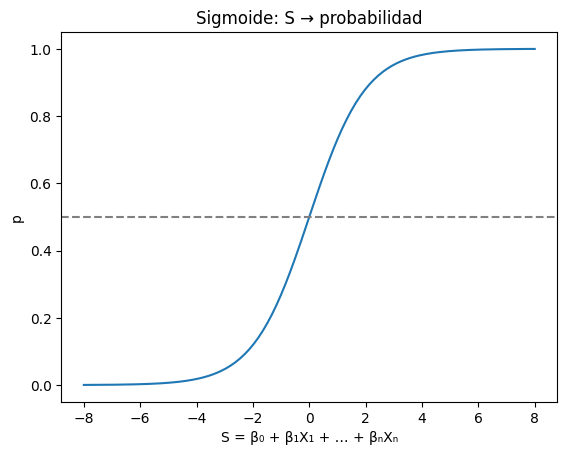

Odds ×e^β por +1 desv.est.:
  bill_length_mm       β=-3.918  →  odds ×0.02
  body_mass_g          β=-0.445  →  odds ×0.64

Corte → sens / esp / prec / FN / FP:
  0.3 → 0.95 | 0.88 | 0.86 | FN=2 | FP=7
  0.5 → 0.95 | 0.93 | 0.91 | FN=2 | FP=4
  0.8 → 0.80 | 1.00 | 1.00 | FN=9 | FP=0

Matriz de confusión (cutoff 0.5):
[[52  4]
 [ 2 42]]


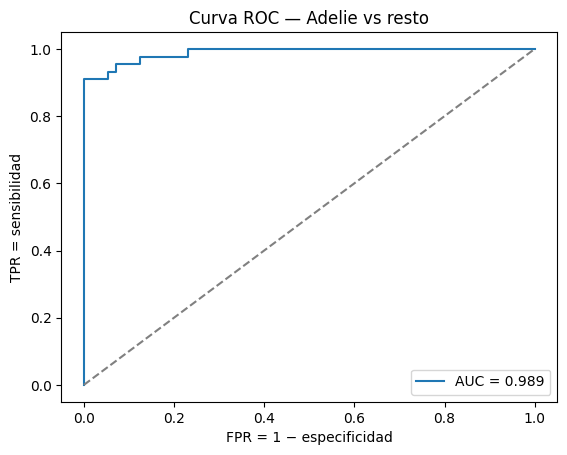


Bayes — 100 personas, 6 enfermas, sens=0.90, esp=0.90:
  TP=5.4 | FP=9.4  →  VPP = 36.49%
  De cada 100 positivos, ~36 están realmente enfermos.


In [1]:
# Ejemplo propio del subgrupo 2C
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# ── 1) La sigmoide: convierte S en probabilidad ──
S = np.linspace(-8, 8, 200)
plt.plot(S, 1 / (1 + np.exp(-S)))
plt.axhline(0.5, ls="--", color="gray")
plt.title("Sigmoide: S → probabilidad")
plt.xlabel("S = β₀ + β₁X₁ + … + βₙXₙ")
plt.ylabel("p")
plt.show()

# ── 2) Problema binario: ¿es Adelie? (1 = sí, 0 = no) ──
pin = sns.load_dataset("penguins").dropna()
pin["es_adelie"] = (pin["species"] == "Adelie").astype(int)

X = pin[["bill_length_mm", "body_mass_g"]]
y = pin["es_adelie"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ── 3) Pipeline: escalar + logística ──
# El escalado es imprescindible: bill_length_mm está en mm (~40)
# y body_mass_g en gramos (~4000). Sin escalar, la masa domina por magnitud.
modelo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
).fit(X_tr, y_tr)

# El modelo entrega probabilidades, no clases
prob = modelo.predict_proba(X_te)[:, 1]

# ── 4) Coeficientes como multiplicadores de odds ──
coef = modelo.named_steps["logisticregression"].coef_[0]
print("Odds ×e^β por +1 desv.est.:")
for nombre, c in zip(X.columns, coef):
    print(f"  {nombre:20s} β={c:+.3f}  →  odds ×{np.exp(c):.2f}")

# ── 5) Efecto del cutoff en sensibilidad y especificidad ──
print("\nCorte → sens / esp / prec / FN / FP:")
for c in [0.3, 0.5, 0.8]:
    pred = (prob >= c).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    sens = tp / (tp + fn)
    esp  = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    print(f"  {c:.1f} → {sens:.2f} | {esp:.2f} | {prec:.2f} | FN={fn} | FP={fp}")

# ── 6) Matriz de confusión en cutoff 0.5 ──
pred05 = (prob >= 0.5).astype(int)
print("\nMatriz de confusión (cutoff 0.5):")
print(confusion_matrix(y_te, pred05))

# ── 7) Curva ROC y AUC (la misma info, para todos los cortes) ──
fpr, tpr, _ = roc_curve(y_te, prob)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_te, prob):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("FPR = 1 − especificidad")
plt.ylabel("TPR = sensibilidad")
plt.title("Curva ROC — Adelie vs resto")
plt.legend()
plt.show()

# ── 8) Bayes con números: 100 personas, 6 enfermas ──
N, prev, sens_b, esp_b = 100, 0.06, 0.90, 0.90
enfermos = N * prev
sanos    = N - enfermos
tp_b = enfermos * sens_b
fp_b = sanos * (1 - esp_b)
vpp  = tp_b / (tp_b + fp_b)
print(f"\nBayes — 100 personas, 6 enfermas, sens=0.90, esp=0.90:")
print(f"  TP={tp_b:.1f} | FP={fp_b:.1f}  →  VPP = {vpp:.2%}")
print(f"  De cada 100 positivos, ~{vpp*100:.0f} están realmente enfermos.")